# M1.1–M1.3 | Image Representation and Pixel Transformations
**Smart Traffic Intelligence System · CV Core Foundation**

## Learning objectives
- Inspect image dimensions, data types, memory and pixel coordinates.
- Understand BGR, RGB, grayscale and HSV representations.
- Extract red regions using HSV thresholding and binary masks.
- Adjust brightness and contrast safely with floating-point arithmetic and clipping.

**Input:** `test1.png`, the supplied traffic scene. Keep it in `data/` relative to the working directory, or beside this notebook. This is a learning experiment, not a validated traffic detector.

## 1. Setup and image loading
OpenCV loads color images in BGR order; Matplotlib expects RGB for color display.

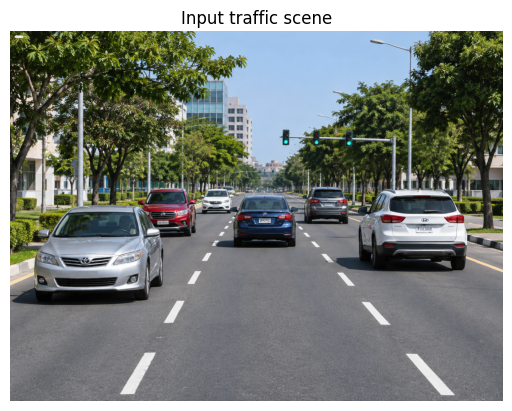

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Support the original project path and a local copy of the supplied image.
image_path = next(
    (path for path in (Path("data/test1.png"), Path("test1.png")) if path.is_file()),
    None,
)
if image_path is None:
    raise FileNotFoundError("Place test1.png in data/ or the working directory.")

image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Could not decode {image_path}")

rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(rgb_image)
plt.title("Input traffic scene")
plt.axis("off")
plt.show()

## 2. Image representation and memory
A color image is a NumPy array of shape `(height, width, channels)`. `size` counts scalar elements, while `nbytes` measures the storage occupied by those elements.

In [2]:
print("Shape:", image.shape)
print("Size:", image.size)
print("Dtype:", image.dtype)
print("Itemsize:", image.itemsize)
print("Nbytes:", image.nbytes)

Shape: (1086, 1448, 3)
Size: 4717584
Dtype: uint8
Itemsize: 1
Nbytes: 4717584


### 2.1. Compare uint8 and uint16
Casting to a wider integer type increases storage without scaling the original pixel values.

In [3]:
image_16 = image.astype(np.uint16)

print("Shape:", image_16.shape)
print("Size:", image_16.size)
print("Dtype:", image_16.dtype)
print("Itemsize:", image_16.itemsize)
print("Nbytes:", image_16.nbytes)
print("Same pixel values:", np.array_equal(image, image_16))

Shape: (1086, 1448, 3)
Size: 4717584
Dtype: uint16
Itemsize: 2
Nbytes: 9435168
Same pixel values: True


## 3. Pixel access and region editing
NumPy indexes pixels as `[y, x]` (row, column). Copy the image before modifying a rectangular region to preserve the original.

In [4]:
x = 100
y = 200

pixel = image[y, x]
print("Pixel BGR:", pixel)

Pixel BGR: [81 88 82]


In [5]:
modified_image = image.copy()

# Paint a 100 × 100 region red using OpenCV's BGR channel order.
modified_image[100:200, 200:300] = [0, 0, 255]

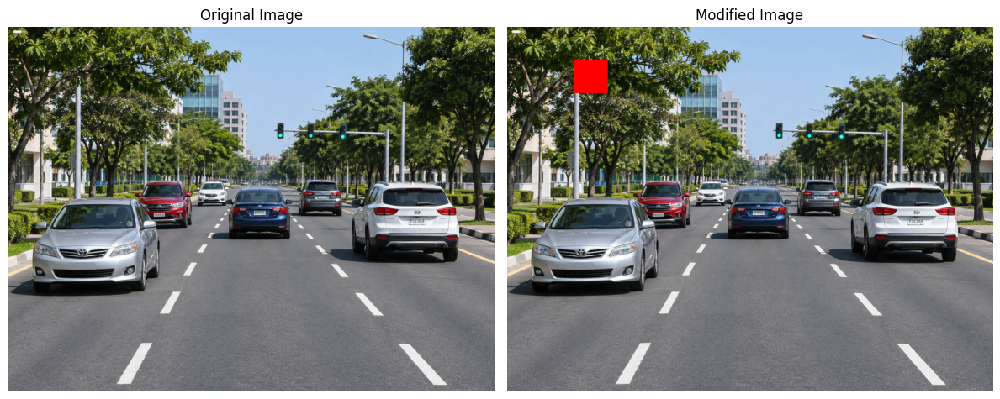

In [6]:
plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Modified image
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(modified_image, cv2.COLOR_BGR2RGB))
plt.title("Modified Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Color channels and color spaces
### 4.1. BGR channel extraction
Each channel stores intensity independently. A grayscale view of the red channel shows red intensity, not a red-colored image.

In [7]:
blue_channel = image[:, :, 0]
green_channel = image[:, :, 1]
red_channel = image[:, :, 2]

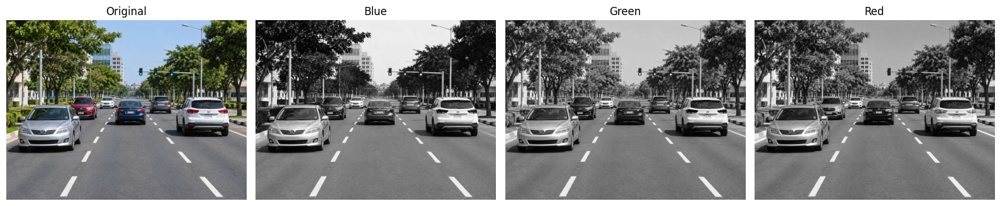

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, channel) in zip(axes, [
    ("Original", rgb_image), ("Blue", blue_channel),
    ("Green", green_channel), ("Red", red_channel),
]):
    ax.imshow(channel, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.2. BGR versus RGB
Passing BGR directly to Matplotlib swaps the apparent red and blue colors. The conversion corrects the display without changing the scene.

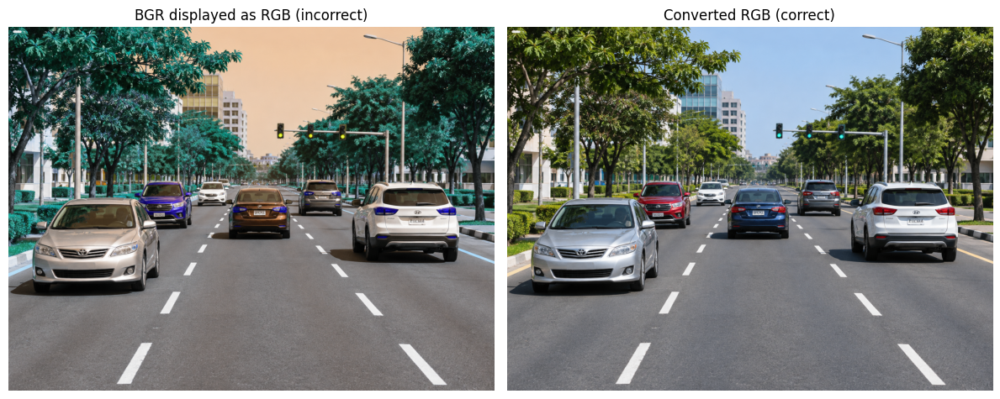

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("BGR displayed as RGB (incorrect)")
axes[1].imshow(rgb_image)
axes[1].set_title("Converted RGB (correct)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.3. Grayscale conversion
The weighted luminance approximation is $Y = 0.114B + 0.587G + 0.299R$. Compare the manual implementation with OpenCV; small rounding differences are possible.

In [10]:
# OpenCV grayscale conversion
gray_cv = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Extract BGR channels
blue = image[:, :, 0]
green = image[:, :, 1]
red = image[:, :, 2]

# Manual grayscale conversion
gray_float = (
    0.114 * blue
    + 0.587 * green
    + 0.299 * red
)

# Round and convert to uint8
gray_manual = np.round(gray_float).astype("uint8")

# Compare results
difference = cv2.absdiff(gray_cv, gray_manual)

print("OpenCV shape:", gray_cv.shape)
print("Manual shape:", gray_manual.shape)
print("OpenCV dtype:", gray_cv.dtype)
print("Manual dtype:", gray_manual.dtype)
print("Maximum difference:", difference.max())
print("Mean absolute difference:", difference.mean())
print("Identical pixels:", np.count_nonzero(difference == 0))
print("Total pixels:", difference.size)

OpenCV shape: (1086, 1448)
Manual shape: (1086, 1448)
OpenCV dtype: uint8
Manual dtype: uint8
Maximum difference: 1
Mean absolute difference: 0.00019649888587039467
Identical pixels: 1572219
Total pixels: 1572528


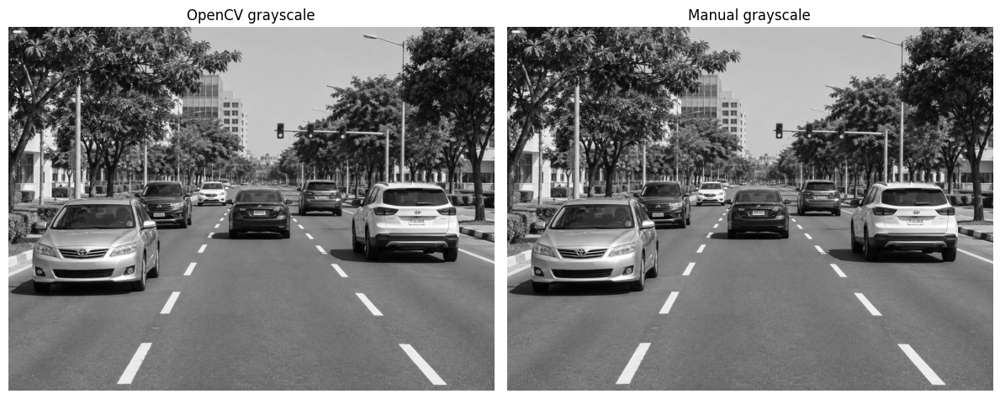

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, gray) in zip(axes, [("OpenCV grayscale", gray_cv), ("Manual grayscale", gray_manual)]):
    ax.imshow(gray, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.4. HSV representation
Hue describes color, saturation describes color purity, and value describes brightness. OpenCV uses H in 0–179 and S/V in 0–255 for uint8 HSV images.

In [12]:
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

print("BGR Shape:", image.shape)
print("HSV Shape:", hsv_image.shape)
print("HSV Dtype:", hsv_image.dtype)

BGR Shape: (1086, 1448, 3)
HSV Shape: (1086, 1448, 3)
HSV Dtype: uint8


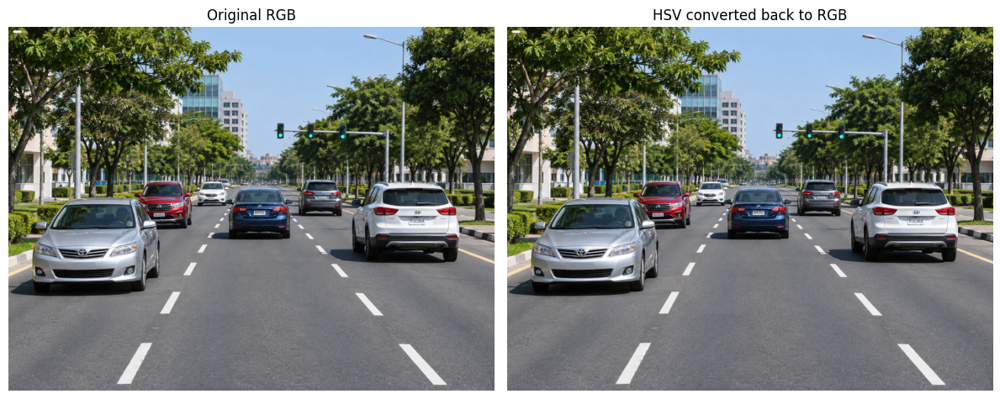

In [13]:
# Extract HSV channels before plotting.
hue, saturation, value = cv2.split(hsv_image)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb_image)
axes[0].set_title("Original RGB")
axes[1].imshow(cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB))
axes[1].set_title("HSV converted back to RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

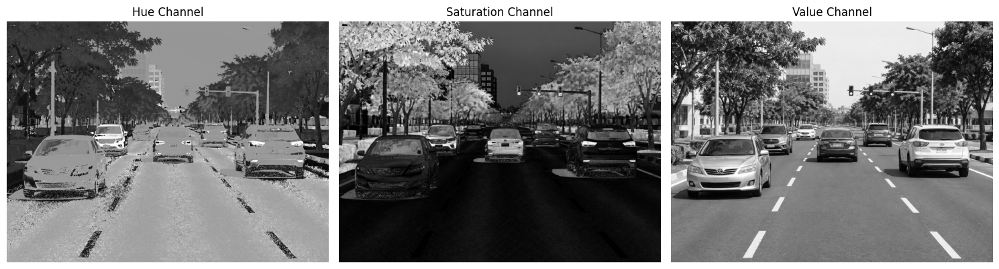

In [14]:
# Plot HSV channels
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(hue, cmap="gray", vmin=0, vmax=179)
plt.title("Hue Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(saturation, cmap="gray", vmin=0, vmax=255)
plt.title("Saturation Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(value, cmap="gray", vmin=0, vmax=255)
plt.title("Value Channel")
plt.axis("off")

plt.tight_layout()
plt.show()

## 5. HSV color masking
### 5.1. First red hue interval
`inRange` returns a binary mask: 255 for matching pixels and 0 otherwise. The thresholds here are experimental, not universal.

In [15]:
lower_red = np.array([0, 100, 70])
upper_red = np.array([10, 255, 255])

red_mask = cv2.inRange(hsv_image, lower_red, upper_red)

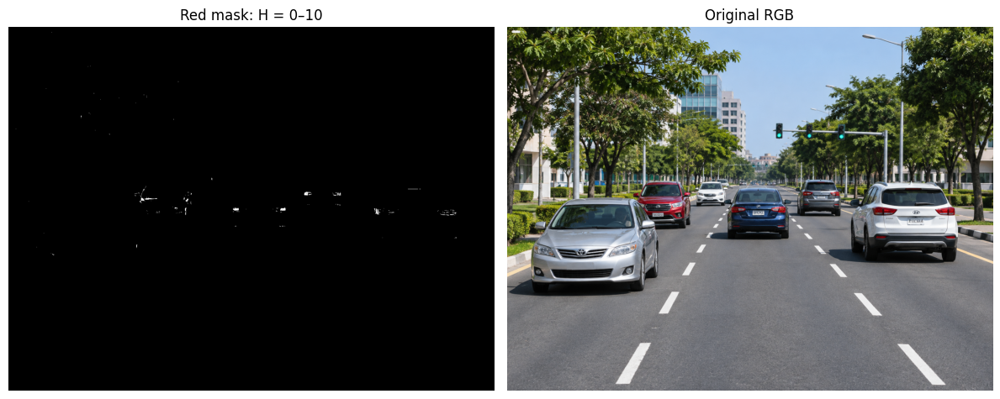

In [16]:
def show_mask(mask: np.ndarray, title: str) -> None:
    """Compare a binary mask with the original RGB image."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[0].set_title(title)
    axes[1].imshow(rgb_image)
    axes[1].set_title("Original RGB")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_mask(red_mask, "Red mask: H = 0–10")

### 5.2. Saturation threshold experiment
Increasing the lower saturation threshold rejects less saturated pixels. With other bounds unchanged, the selected pixel count cannot increase.

In [17]:
lower_red_150 = np.array([0, 150, 70])

red_mask_150 = cv2.inRange(
    hsv_image,
    lower_red_150,
    upper_red
)

print("S >= 100:", cv2.countNonZero(red_mask))
print("S >= 150:", cv2.countNonZero(red_mask_150))

S >= 100: 1299
S >= 150: 938


### 5.3. Second red hue interval
Hue is circular; red also occurs near the upper end of the OpenCV hue range.

In [18]:
lower_red_2 = np.array([170, 100, 70])
upper_red_2 = np.array([179, 255, 255])

red_mask_2 = cv2.inRange(
    hsv_image,
    lower_red_2,
    upper_red_2
)

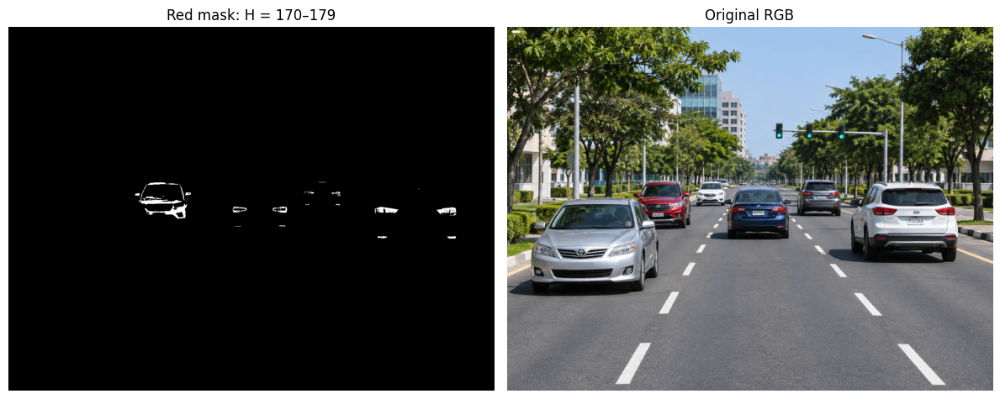

In [19]:
show_mask(red_mask_2, "Red mask: H = 170–179")

### 5.4. Combine masks and extract red regions
Use bitwise OR to include both red intervals, then apply the combined mask to the original image. The masked image remains BGR until converted for display.

In [20]:
red_mask_combined = cv2.bitwise_or(red_mask, red_mask_2)

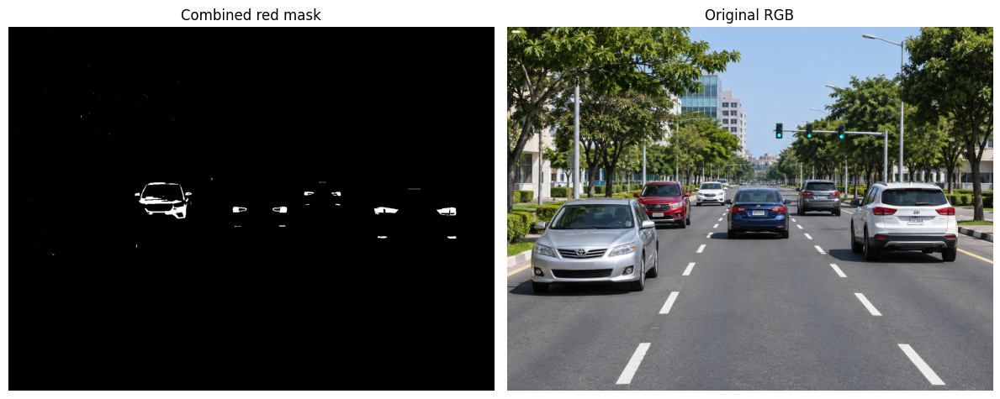

In [21]:
show_mask(red_mask_combined, "Combined red mask")

In [22]:
red_result = cv2.bitwise_and(
    image,
    image,
    mask=red_mask_combined
)  # Output remains BGR.

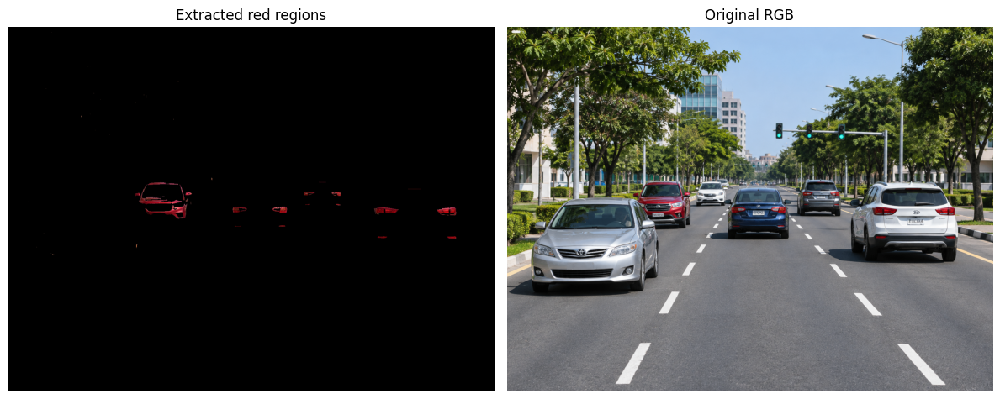

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(red_result, cv2.COLOR_BGR2RGB))
axes[0].set_title("Extracted red regions")
axes[1].imshow(rgb_image)
axes[1].set_title("Original RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. M1.3 — Brightness and contrast
*Added from the current mentoring session to consolidate the related experiment.*

The linear transformation is $I_{out}=\alpha I_{in}+\beta$. Alpha scales intensity differences before clipping; beta shifts intensities. Scaling around zero can also change brightness. Convert to floating point before arithmetic, clip to [0, 255], then round and cast to uint8.

In [24]:
def adjust_brightness_contrast(
    image: np.ndarray,
    alpha: float = 1.0,
    beta: float = 0.0,
) -> np.ndarray:
    """Scale and shift intensities of a uint8 image, returning uint8."""
    adjusted = image.astype(np.float32) * alpha + beta
    # Saturate values rather than allowing integer wraparound.
    np.clip(adjusted, 0, 255, out=adjusted)
    return np.rint(adjusted).astype(np.uint8)

### 6.1. Compare transformations
Inspect shadows, vehicle details and bright road markings for changes and saturation.

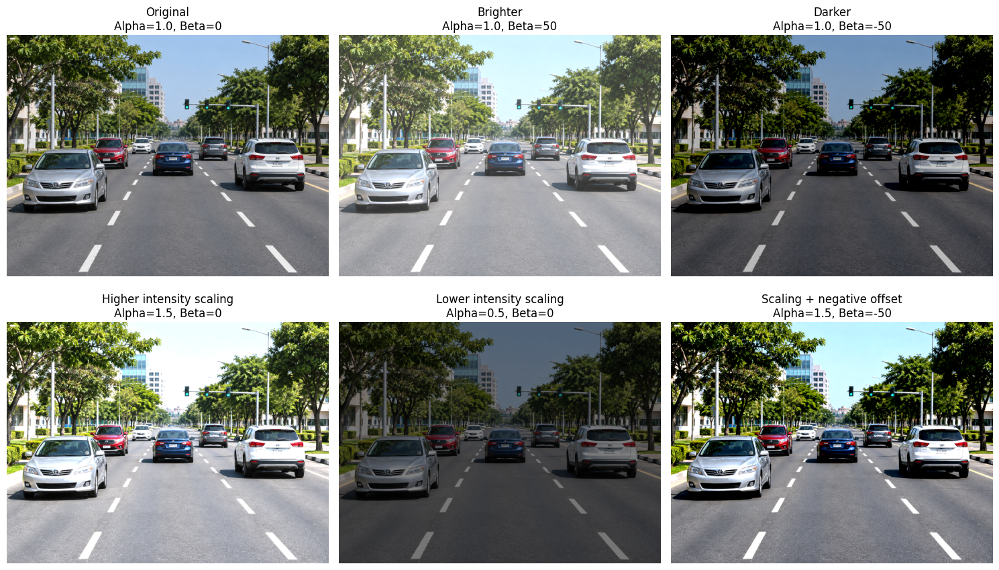

In [25]:
experiments = [
    ("Original", 1.0, 0),
    ("Brighter", 1.0, 50),
    ("Darker", 1.0, -50),
    ("Higher intensity scaling", 1.5, 0),
    ("Lower intensity scaling", 0.5, 0),
    ("Scaling + negative offset", 1.5, -50),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (title, alpha, beta) in zip(axes.ravel(), experiments):
    adjusted = adjust_brightness_contrast(rgb_image, alpha, beta)
    ax.imshow(adjusted)
    ax.set_title(f"{title}\nAlpha={alpha}, Beta={beta}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Verification
Assertions check exact values, output type, clipping and identity behavior. A failed assertion raises an error rather than silently accepting an incorrect result.

In [26]:
pixels = np.array([0, 50, 100, 200, 255], dtype=np.uint8)
result = adjust_brightness_contrast(pixels, alpha=1.5, beta=20)
expected = np.array([20, 95, 170, 255, 255], dtype=np.uint8)

assert np.array_equal(result, expected), "Unexpected pixel values"
assert result.dtype == np.uint8, "Incorrect output type"
assert np.array_equal(adjust_brightness_contrast(image), image), "Identity failed"
assert np.array_equal(
    adjust_brightness_contrast(np.array([30], dtype=np.uint8), beta=-50),
    np.array([0], dtype=np.uint8),
), "Lower clipping failed"
assert cv2.countNonZero(red_mask_150) <= cv2.countNonZero(red_mask)
print("All tests passed!")

All tests passed!


## 8. Takeaways and next steps
- Image dtype and channel order matter for correct arithmetic and visualization.
- HSV masking is a useful color-based experiment, but it is sensitive to illumination and does not identify vehicles reliably on its own.
- Clipping prevents wraparound but may discard highlight or shadow detail.
- Next: review the transformations and promote tested reusable functions to `cv_core` when ready. No package or Git changes are made by this notebook.